# Loss Function:
- we currently have the essence of the bigram model implemented here
- however, to make it better, we would have to define a single number that shows how good our language model is (loss function ofcourse)
- now, the main question is, how would you evaluate the current iteration of the model to give out a loss number

## Summary of this part:
1. Goal: maximize likelihood (product of proba) with respect to model parameters (probability table right now, weights and biases in the future)
2. this goal is equivalent to maximizing the log likelihood (because log is monotonic, means optimization is equally as effective)
3. equivalent to minimizing negative log likelihood
4. in practice, equivalent to minimizing the average negative log likelihood

In [10]:
# Code from previous parts needed (old stuff, nothing new)


import torch

words = open('names.txt', 'r').read().splitlines()
words[len(words) - 1000: len(words) - 990]

N = torch.zeros((27, 27), dtype=torch.int32)
chars =sorted(list(set(''.join(words)))) # sorted list of all the characters

s_to_i = {s: i+1 for i, s in enumerate(chars)}
s_to_i['.'] = 0 # explicit mapping for special character
# shift s_to_i indexing by 1 to accomodate for special to have index 0
i_to_s = {i:s for s, i in s_to_i.items()}

for w in words:
    chars = ['.'] + list(w) + ['.']
    
    for char_1, char_2 in zip(chars, chars[1:]): # two at a time
        char1_idx = s_to_i[char_1]
        char2_idx = s_to_i[char_2]

        N[char1_idx, char2_idx] += 1
   
P = N.float()
row_totals = P.sum(1, keepdim=True)
P /= row_totals 

g = torch.Generator().manual_seed(2147483647) # generator object to make it deterministic

for i in range(10):
    generated_name = ""
    cur = 0 # beginning index 0
    while True:
        p = P[cur]
        cur = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item() 
        generated_name += i_to_s[cur]
        if cur == 0:
            break # the special symbol encountered, so end word
    print(generated_name)
    

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [18]:
# Let's take for example the probabilities according to the bigram model (no training yet), on a single word:
for w in words[:1]:
    chars = ['.'] + list(w) + ['.']
    
    for char_1, char_2 in zip(chars, chars[1:]): # two at a time
        char1_idx = s_to_i[char_1]
        char2_idx = s_to_i[char_2]
        proba = P[char1_idx, char2_idx]

        print(f'proba {char_1}{char_2}: {proba:.4f}')

proba .e: 0.0478
proba em: 0.0377
proba mm: 0.0253
proba ma: 0.3899
proba a.: 0.1960


In an ideal world:
- if the bigram is completely untrained, proba of all should be 1/27 ~ 0.037
- if the bigram is perfectly trained, proba of all the above should be 1 (the model is correctly predicting what is coming after)

## Validation of a Good Model:
- the product of probabilities within a single word (so like all of the probabilities printed for `emma` above) should be as high as possible
- this "product of probabilities" is called the likelihood of occurrence
- since the probabilities above will be smaller than 1, and the resultant product of probabilities will be SUPER small, we are better off dealing with log of probabilities instead just to give us some breathing room to work with

## Log Probability Starting to Resemble Loss:
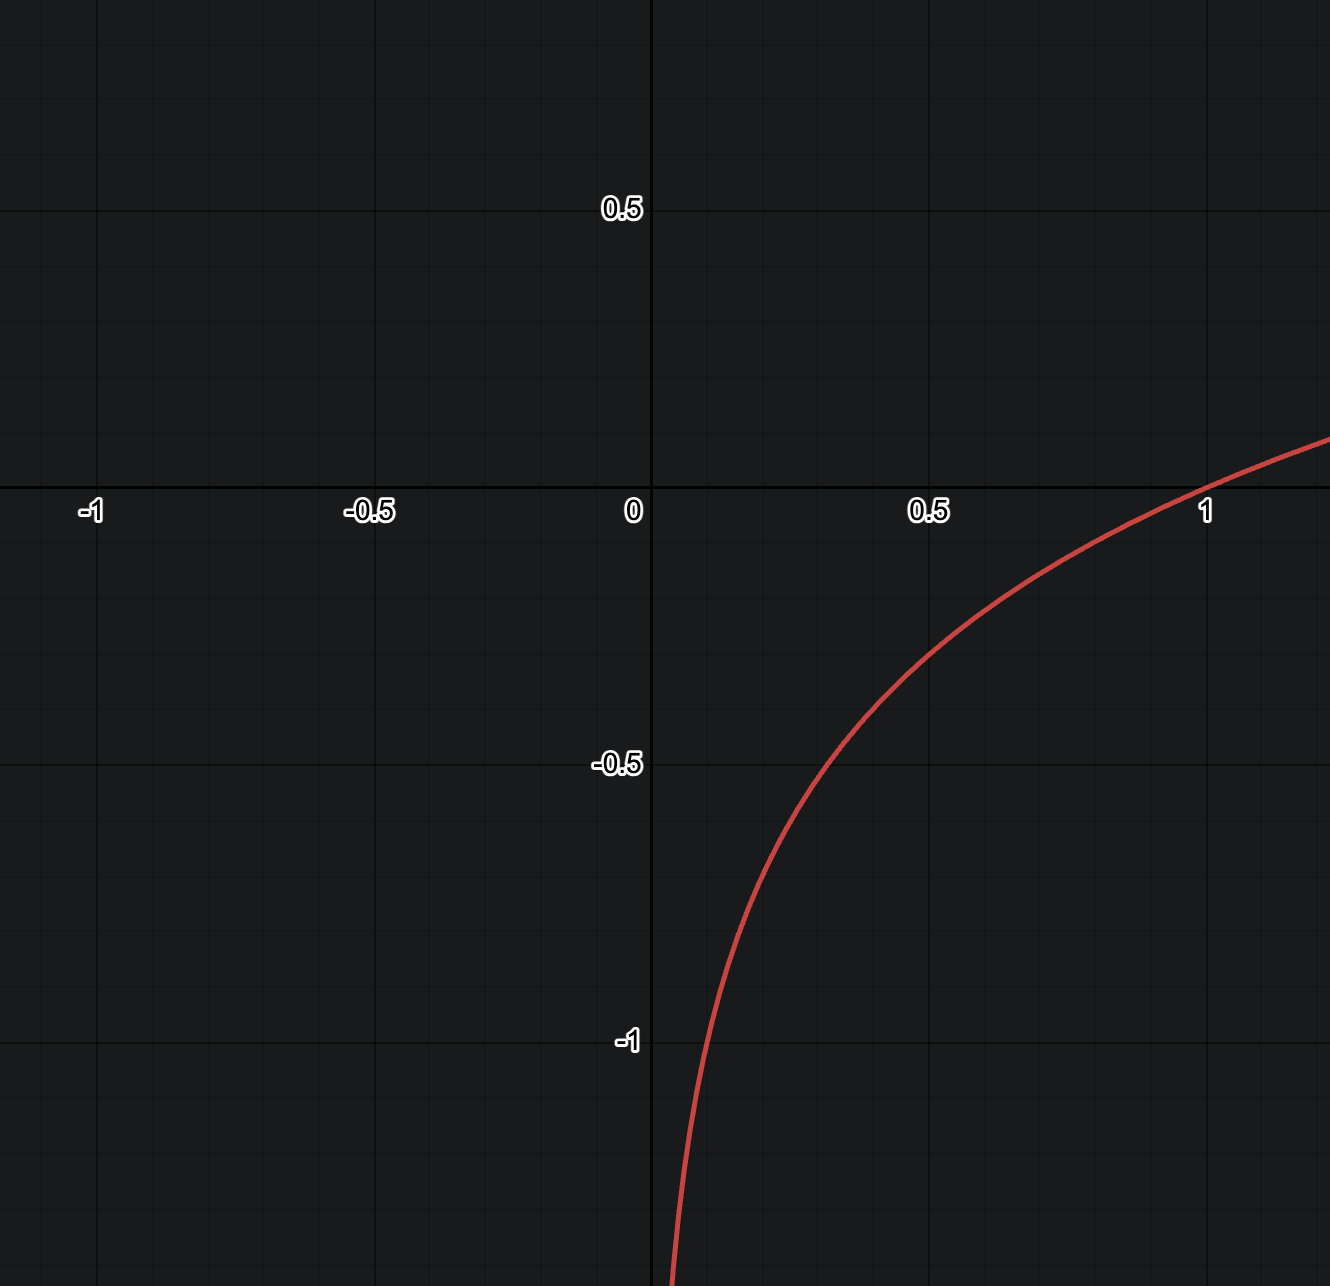
- here, any log(P) values that are very small converge to -inf -> GOOD, more small means more negative means BAD
- what log also does is makes it so that multiplication now becomes addition with probabilities: $log(abc) = log(a) + log(b) + log(c)$
- here, a = log prob of a, i.e. some combination of character from happening; b is the probability of that prev character and some other char happening, etc etc

In [22]:
log_likelihood = 0.0 # accumulated
for w in words[:3]:
    chars = ['.'] + list(w) + ['.']
    
    for char_1, char_2 in zip(chars, chars[1:]): # two at a time
        char1_idx = s_to_i[char_1]
        char2_idx = s_to_i[char_2]
        log_proba = torch.log(P[char1_idx, char2_idx])
        log_likelihood += log_proba

        print(f'log proba {char_1}{char_2}: {log_proba:.4f}')
print("log likelihood:", log_likelihood)

log proba .e: -3.0408
log proba em: -3.2793
log proba mm: -3.6772
log proba ma: -0.9418
log proba a.: -1.6299
log proba .o: -4.3982
log proba ol: -2.5508
log proba li: -1.7278
log proba iv: -4.1867
log proba vi: -1.0383
log proba ia: -1.9796
log proba a.: -1.6299
log proba .a: -1.9829
log proba av: -3.7045
log proba va: -1.3882
log proba a.: -1.6299
log likelihood: tensor(-38.7856)


## Approaching a concept for the Loss Function:
- we see that the log likelihood yields a negative number
- but when we deal with loss functions, what the semantics is, is "lower is better" (although we mean it with the context of as low to 0)
- but here, just to make things easier for us and we don't go crazy needing to remember that (we need to take the negative value closer to 0), we generalize and make this log likelihood positive and go for smaller and smaller after optimizations (loss being negative trips that lower thing up)
- Negative Log Likelihood gives us the proper loss function for the bigram model

In [26]:
neg_log_likelihood = -log_likelihood
print("neg log likelihood (loss):", neg_log_likelihood)

neg log likelihood (loss): tensor(38.7856)


## Improving our current defn of Loss:
- instead of just having the NLL as the loss function, we can go one step further and use the average NLL as our loss function
- what this does is tell a good story about the entire training set converged as one word / name / cities / whatever you're using

In [27]:
log_likelihood = 0.0 # accumulated
n = 0

for w in words[:3]:
    chars = ['.'] + list(w) + ['.']
    
    for char_1, char_2 in zip(chars, chars[1:]): # two at a time
        char1_idx = s_to_i[char_1]
        char2_idx = s_to_i[char_2]
        log_proba = torch.log(P[char1_idx, char2_idx])
        log_likelihood += log_proba
        n += 1

        print(f'log proba {char_1}{char_2}: {log_proba:.4f}')
print("avg neg log likelihood:", neg_log_likelihood / n) # we want this number as small as possible

log proba .e: -3.0408
log proba em: -3.2793
log proba mm: -3.6772
log proba ma: -0.9418
log proba a.: -1.6299
log proba .o: -4.3982
log proba ol: -2.5508
log proba li: -1.7278
log proba iv: -4.1867
log proba vi: -1.0383
log proba ia: -1.9796
log proba a.: -1.6299
log proba .a: -1.9829
log proba av: -3.7045
log proba va: -1.3882
log proba a.: -1.6299
avg neg log likelihood: tensor(2.4241)


## Model Smoothing with Fake Counts:
- this model is designed to work on any names list, not just the training data
- there is a possibility the training data never saw a bigram conbination that might be seen in the test data (like Andrej wasn't in the dataset for example, in our `names.txt`, there was no observation of `"ej"`, therefore the model fails because it tries to do log(0) = -inf -> the model fails here
- Smoothing: Add a count of 1 to literally all the entries in the table
- The code for smoothing looks like this:

```python
P = (N+1).float() # Ensures there are no 0s, therefore nothing will be infinity likely
P /= P.sum(1, keepdims=True)
```